# Dual-Path Brain Tumor Understanding: Segmentation + Text Generation
## FLAIR MRI (BraTS 2020) + Radiology Reports (TextBraTS 2020)
---
**Path A (Segmentation):** Image + Text Embedding → Segmentation Mask
  Evaluate: Dice, IoU vs. ground-truth mask
#
**Path B (Text Generation):** Image → Generated Text Description
  Evaluate: ROUGE, BLEU vs. ground-truth text
#
**Correlation:** Per-sample Dice (A) vs ROUGE-L (B) → Spearman ρ proves both
  pathways genuinely understand the tumor.

In [30]:
# Install required dependencies
!pip install -q segmentation-models-pytorch scikit-learn rouge_score nltk transformers

In [31]:
import os
import glob
import re
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from scipy.spatial.distance import directed_hausdorff
from scipy.stats import spearmanr

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from rouge_score import rouge_scorer

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import torchvision.transforms as T
import segmentation_models_pytorch as smp

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using Device: {DEVICE}")

Using Device: cuda


## 1. Configuration & Paths

In [32]:
class Config:
    # Paths
    IMG_TRAIN_DIR = "/kaggle/input/datasets/hussainnasirkhan/flair-brats2020/FLAIR_BRATS2020_split/train"
    IMG_VAL_DIR   = "/kaggle/input/datasets/hussainnasirkhan/flair-brats2020/FLAIR_BRATS2020_split/val"
    TEXT_DATA_DIR = "/kaggle/input/datasets/athidathank/textbrats/TextBraTSData"

    # Model Parameters
    IMG_SIZE    = 128
    TEXT_DIM    = 768       # Precomputed embedding dimension (Path A)
    IN_CHANNELS = 3
    NUM_CLASSES = 1

    # Caption model parameters (Path B)
    VOCAB_SIZE    = 3000    # max vocabulary size
    EMBED_DIM     = 256
    HIDDEN_DIM    = 512
    MAX_SEQ_LEN   = 64      # max tokens per report
    ENC_FEAT_DIM  = 512     # ResNet34 bottleneck channels

    # Training Parameters
    EPOCHS       = 30
    CAP_EPOCHS   = 20       # Path B captioning epochs
    BATCH_SIZE   = 32
    LR           = 1e-4
    WEIGHT_DECAY = 1e-4
    PATIENCE     = 7
    MIN_TUMOR_PIXELS = 50

    # Checkpoints
    CHECKPOINT_PATH     = "/kaggle/working/best_text_guided_model.pth"
    BASELINE_CHECKPOINT = "/kaggle/working/best_baseline_model.pth"
    CAPTION_CHECKPOINT  = "/kaggle/working/best_caption_model.pth"

    LOAD_CHECKPOINT = False
    RUN_NOTEBOOK    = True

cfg = Config()

## 2. Tokenizer Setup (Path B)
We use the pretrained GPT-2 tokenizer — no need to build a custom vocabulary.
It provides a 50K subword vocab with BOS/EOS tokens out of the box.

In [33]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")
# GPT-2 has no pad token by default — reuse EOS as PAD (standard practice)
tokenizer.pad_token = tokenizer.eos_token

PAD_IDX = tokenizer.pad_token_id    # == eos_token_id for GPT-2 (50256)
SOS_IDX = tokenizer.bos_token_id    # 50256 (same token; GPT-2 uses EOS as BOS)
EOS_IDX = tokenizer.eos_token_id    # 50256
VOCAB_SIZE = len(tokenizer)         # 50257

print(f"Tokenizer: GPT-2  |  Vocab size: {VOCAB_SIZE}  |  PAD/EOS id: {PAD_IDX}")


def tokenize_text(text, max_len=64):
    """Encode a string to a fixed-length int64 numpy array."""
    enc = tokenizer(
        text,
        max_length=max_len,
        truncation=True,
        padding='max_length',
        return_tensors='np',
    )
    return enc['input_ids'][0].astype(np.int64)  # (max_len,)


def decode_ids(ids):
    """Decode a list/array of token ids back to a string."""
    return tokenizer.decode(ids, skip_special_tokens=True)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer: GPT-2  |  Vocab size: 50257  |  PAD/EOS id: 50256


## 3. Data Loading & Preprocessing
The dataset returns:
- `img`        : (3, H, W) MRI slice
- `mask`       : (1, H, W) binary segmentation mask
- `text_emb`   : (768,) precomputed embedding **for Path A**
- `caption_ids`: (MAX_SEQ_LEN,) GPT-2 token ids **for Path B**
- `raw_text`   : str ground-truth report **for ROUGE/BLEU evaluation**
- `patient_id` : str

In [34]:
class BraTSMultimodalDataset(Dataset):
    def __init__(self, img_dir, text_dir, split="train", augment=False):
        self.img_dir  = img_dir
        self.text_dir = text_dir
        self.split    = split
        self.augment  = augment

        self.img_files  = sorted(glob.glob(os.path.join(img_dir, "images", "image_*.npy")))
        self.mask_files = sorted(glob.glob(os.path.join(img_dir, "masks",  "mask_*.npy")))

        self.slices = []
        print(f"Building {split} dataset index...")
        for img_path in self.img_files:
            m = re.search(r'image_(\d+)\.npy', os.path.basename(img_path))
            if not m:
                continue
            idx = int(m.group(1))
            if idx == 0:
                continue  # no text match

            mask_path = img_path.replace("images", "masks").replace("image_", "mask_")
            if not os.path.exists(mask_path):
                continue

            patient_id = f"BraTS20_Training_{idx:03d}"
            emb_path   = os.path.join(text_dir, patient_id, f"{patient_id}_flair_text.npy")
            txt_path   = os.path.join(text_dir, patient_id, f"{patient_id}_flair_text.txt")

            if not os.path.exists(emb_path):
                continue

            raw_text = ""
            if os.path.exists(txt_path):
                try:
                    with open(txt_path, 'r', encoding='utf-8') as fh:
                        raw_text = fh.read().strip()
                except Exception:
                    pass

            mask_vol = np.load(mask_path)
            binary_mask = (mask_vol[..., 1:].sum(axis=-1) > 0).astype(np.float32)

            for s in range(binary_mask.shape[0]):
                if binary_mask[s].sum() >= cfg.MIN_TUMOR_PIXELS:
                    self.slices.append({
                        "img_path":   img_path,
                        "mask_path":  mask_path,
                        "emb_path":   emb_path,
                        "raw_text":   raw_text,
                        "slice_idx":  s,
                        "patient_id": patient_id,
                    })

        print(f"  -> Found {len(self.slices)} usable slices for {split}.")

    def __len__(self):
        return len(self.slices)

    def __getitem__(self, idx):
        item = self.slices[idx]
        s    = item["slice_idx"]

        img_vol  = np.load(item["img_path"],  mmap_mode='r')
        mask_vol = np.load(item["mask_path"], mmap_mode='r')

        img  = img_vol[s].astype(np.float32)
        mask = (mask_vol[s, ..., 1:].sum(axis=-1) > 0).astype(np.float32)

        if self.augment:
            if random.random() > 0.5:
                img  = np.fliplr(img).copy()
                mask = np.fliplr(mask).copy()
            if random.random() > 0.5:
                img  = np.flipud(img).copy()
                mask = np.flipud(mask).copy()

        img  = (img - img.min()) / (img.max() - img.min() + 1e-8)
        img  = np.stack([img, img, img], axis=0)   # (3, H, W)
        mask = mask[np.newaxis, ...]                 # (1, H, W)

        # Path A: precomputed embedding
        text_emb = np.load(item["emb_path"])         # (1, seq, 768)
        text_emb = text_emb[0].mean(axis=0).astype(np.float32)  # (768,)

        # Path B: GPT-2 tokenised caption
        raw_text    = item["raw_text"]
        caption_ids = tokenize_text(raw_text, max_len=cfg.MAX_SEQ_LEN)

        return (
            torch.from_numpy(img),
            torch.from_numpy(mask),
            torch.from_numpy(text_emb),
            torch.from_numpy(caption_ids),
            raw_text,
            item["patient_id"],
        )


# collate_fn needed because raw_text is a plain string (can't be auto-batched as tensor)
def collate_fn(batch):
    imgs, masks, embs, caps, texts, pids = zip(*batch)
    return (
        torch.stack(imgs),
        torch.stack(masks),
        torch.stack(embs),
        torch.stack(caps),
        list(texts),
        list(pids),
    )


try:
    train_ds = BraTSMultimodalDataset(cfg.IMG_TRAIN_DIR, cfg.TEXT_DATA_DIR, split="train", augment=True)
    val_ds   = BraTSMultimodalDataset(cfg.IMG_VAL_DIR,   cfg.TEXT_DATA_DIR, split="val",   augment=False)

    train_loader = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE, shuffle=True,  num_workers=2,
                              pin_memory=True, collate_fn=collate_fn)
    val_loader   = DataLoader(val_ds,   batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=2,
                              pin_memory=True, collate_fn=collate_fn)

    print("\nDataset loaded successfully.")
    sample_imgs, sample_masks, sample_embs, sample_caps, sample_texts, _ = next(iter(train_loader))
    print(f"Image Batch     : {sample_imgs.shape}")
    print(f"Mask Batch      : {sample_masks.shape}")
    print(f"Text Emb Batch  : {sample_embs.shape}")
    print(f"Caption ID Batch: {sample_caps.shape}")
    print(f"Example text    : {sample_texts[0][:80]}")
except Exception as e:
    print(f"Could not load datasets. Error: {e}")

Building train dataset index...
  -> Found 14581 usable slices for train.
Building val dataset index...
  -> Found 5064 usable slices for val.

Dataset loaded successfully.
Image Batch     : torch.Size([32, 3, 128, 128])
Mask Batch      : torch.Size([32, 1, 128, 128])
Text Emb Batch  : torch.Size([32, 768])
Caption ID Batch: torch.Size([32, 64])
Example text    : The lesion area is in the frontal and parietal lobes with a mixed pattern of hig


## 4. Path A — Model Architecture: Text-Guided Segmentation
ResNet34 U-Net backbone with late fusion of text embeddings.

In [35]:
class TextGuidedUNet(nn.Module):
    def __init__(self, text_dim=768, use_text=True):
        super().__init__()
        self.use_text = use_text

        self.unet = smp.Unet(
            encoder_name="resnet34",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1,
        )

        if self.use_text:
            self.text_proj = nn.Sequential(
                nn.Linear(text_dim, 512),
                nn.ReLU(),
                nn.Dropout(0.1),
                nn.Linear(512, 256),
                nn.ReLU(),
            )
            self.fusion = nn.Sequential(
                nn.Conv2d(1 + 256, 64, kernel_size=3, padding=1),
                nn.BatchNorm2d(64),
                nn.ReLU(),
                nn.Dropout2d(0.1),
                nn.Conv2d(64, 1, kernel_size=1),
            )

    def forward(self, img, text_emb=None):
        seg_out = self.unet(img)  # (B, 1, H, W)

        if self.use_text and text_emb is not None:
            t = self.text_proj(text_emb)                          # (B, 256)
            t = t[:, :, None, None].expand(-1, -1, img.shape[2], img.shape[3])
            fused = torch.cat([seg_out, t], dim=1)                # (B, 257, H, W)
            return self.fusion(fused)

        return seg_out


print("Path A — TextGuidedUNet:")
seg_model = TextGuidedUNet(use_text=True).to(DEVICE)
print(f"  Total Params: {sum(p.numel() for p in seg_model.parameters())/1e6:.2f} M")

Path A — TextGuidedUNet:
  Total Params: 25.11 M


## 5. Path B — Model Architecture: Image Captioning
Shared ResNet34 encoder (weights transferred from seg model after training) →
Global Avg Pool → Linear Projection → LSTM Decoder with attention.

In [36]:
class LSTMDecoder(nn.Module):
    """Single-layer LSTM decoder with additive attention over encoder features."""
    def __init__(self, vocab_size, embed_dim, hidden_dim, enc_feat_dim):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm    = nn.LSTMCell(embed_dim + enc_feat_dim, hidden_dim)
        self.attn_fc = nn.Linear(hidden_dim + enc_feat_dim, 1)
        self.fc_out  = nn.Linear(hidden_dim, vocab_size)
        self.dropout = nn.Dropout(0.3)
        self.hidden_dim   = hidden_dim
        self.enc_feat_dim = enc_feat_dim

    def init_hidden(self, enc_out):
        # enc_out: (B, enc_feat_dim)
        B = enc_out.size(0)
        h = torch.zeros(B, self.hidden_dim, device=enc_out.device)
        c = torch.zeros(B, self.hidden_dim, device=enc_out.device)
        return h, c

    def forward(self, enc_out, captions):
        """
        enc_out:  (B, enc_feat_dim) — projected image bottleneck
        captions: (B, T)            — token ids (including SOS, shifted for teacher forcing)
        Returns logits: (B, T-1, vocab_size)
        """
        B, T = captions.size()
        h, c = self.init_hidden(enc_out)

        outputs = []
        # Teacher forcing: feed ground-truth tokens [SOS .. second-to-last]
        for t in range(T - 1):
            tok_emb  = self.embed(captions[:, t])              # (B, embed_dim)
            lstm_in  = torch.cat([tok_emb, enc_out], dim=1)    # (B, embed_dim + enc_feat_dim)
            h, c     = self.lstm(lstm_in, (h, c))
            logit    = self.fc_out(self.dropout(h))             # (B, vocab_size)
            outputs.append(logit.unsqueeze(1))

        return torch.cat(outputs, dim=1)  # (B, T-1, vocab_size)

    def greedy_decode(self, enc_out, sos_idx, eos_idx, max_len=64):
        """Generate token ids greedily at inference time."""
        B = enc_out.size(0)
        h, c = self.init_hidden(enc_out)
        tok = torch.full((B,), sos_idx, dtype=torch.long, device=enc_out.device)

        generated = []
        for _ in range(max_len):
            tok_emb = self.embed(tok)
            lstm_in = torch.cat([tok_emb, enc_out], dim=1)
            h, c    = self.lstm(lstm_in, (h, c))
            logit   = self.fc_out(h)                            # (B, vocab_size)
            tok     = logit.argmax(dim=-1)                      # (B,)
            generated.append(tok.unsqueeze(1))

        return torch.cat(generated, dim=1)  # (B, max_len)


class ImageCaptionModel(nn.Module):
    """
    Path B: Image → Generated radiology text.
    Encoder = ResNet34 (shared with seg model, weights loaded after seg training).
    """
    def __init__(self, vocab_size, embed_dim=256, hidden_dim=512,
                 enc_feat_dim=512, proj_dim=256):
        super().__init__()

        # Encoder: ResNet34 feature extractor (we borrow the smp encoder)
        _tmp = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                        in_channels=3, classes=1)
        self.encoder = _tmp.encoder   # outputs list; we use [-1]: (B,512,H',W')
        del _tmp

        self.gap     = nn.AdaptiveAvgPool2d(1)                   # → (B, 512, 1, 1)
        self.proj    = nn.Sequential(
            nn.Linear(enc_feat_dim, proj_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
        )
        self.decoder = LSTMDecoder(vocab_size, embed_dim, hidden_dim, proj_dim)

    def encode(self, img):
        feats    = self.encoder(img)[-1]                         # (B, 512, h, w)
        pooled   = self.gap(feats).squeeze(-1).squeeze(-1)      # (B, 512)
        enc_out  = self.proj(pooled)                             # (B, proj_dim)
        return enc_out

    def forward(self, img, captions):
        enc_out = self.encode(img)
        logits  = self.decoder(enc_out, captions)                # (B, T-1, vocab_size)
        return logits

    def generate(self, img, sos_idx, eos_idx, max_len=64):
        enc_out = self.encode(img)
        return self.decoder.greedy_decode(enc_out, sos_idx, eos_idx, max_len)


print("\nPath B — ImageCaptionModel:")
cap_model = ImageCaptionModel(
    vocab_size=VOCAB_SIZE,       # 50257 from GPT-2 tokenizer
    embed_dim=cfg.EMBED_DIM,
    hidden_dim=cfg.HIDDEN_DIM,
    enc_feat_dim=cfg.ENC_FEAT_DIM,
    proj_dim=cfg.EMBED_DIM,
).to(DEVICE)
print(f"  Total Params: {sum(p.numel() for p in cap_model.parameters())/1e6:.2f} M")


Path B — ImageCaptionModel:
  Total Params: 62.17 M


## 6. Loss Functions

In [37]:
class SegmentationLoss(nn.Module):
    def __init__(self, dice_w=0.5, bce_w=0.5, smooth=1e-6):
        super().__init__()
        self.bce    = nn.BCEWithLogitsLoss()
        self.dice_w = dice_w
        self.bce_w  = bce_w
        self.smooth = smooth

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs    = torch.sigmoid(logits)
        flat_p   = probs.view(-1)
        flat_t   = targets.view(-1)
        inter    = (flat_p * flat_t).sum()
        dice_l   = 1 - (2 * inter + self.smooth) / (flat_p.sum() + flat_t.sum() + self.smooth)
        return self.bce_w * bce_loss + self.dice_w * dice_l


class CaptionLoss(nn.Module):
    """Cross-entropy on predicted tokens vs. target tokens (teacher forcing)."""
    def __init__(self, pad_idx=0):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(ignore_index=pad_idx)

    def forward(self, logits, targets):
        # logits:  (B, T-1, vocab_size)
        # targets: (B, T) — we want tokens [1:] (everything after SOS)
        B, Tm1, V = logits.size()
        return self.ce(logits.reshape(B * Tm1, V), targets[:, 1:].reshape(-1))


def compute_seg_metrics(logits, targets, thresh=0.5):
    probs = torch.sigmoid(logits).detach()
    preds = (probs > thresh).float()
    tgts  = targets.detach()
    smooth = 1e-6
    TP = (preds * tgts).sum()
    FP = (preds * (1 - tgts)).sum()
    FN = ((1 - preds) * tgts).sum()
    dice = (2*TP + smooth) / (2*TP + FP + FN + smooth)
    iou  = (TP + smooth) / (TP + FP + FN + smooth)
    return dice.item(), iou.item()

## 7. Path A — Training: Text-Guided Segmentation

In [38]:
def train_seg_model(model, train_loader, val_loader, checkpoint_path, epochs):
    criterion = SegmentationLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    scaler    = GradScaler()

    history = {'train_loss': [], 'val_loss': [], 'train_dice': [], 'val_dice': [],
               'train_iou': [], 'val_iou': []}
    best_dice, patience_counter = 0.0, 0

    for epoch in range(epochs):
        model.train()
        t_loss, t_dice, t_iou = 0, 0, 0

        for imgs, masks, embs, _, _, _ in train_loader:
            imgs, masks, embs = imgs.to(DEVICE), masks.to(DEVICE), embs.to(DEVICE)
            optimizer.zero_grad()
            with autocast():
                logits = model(imgs, embs)
                loss   = criterion(logits, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            d, i    = compute_seg_metrics(logits, masks)
            t_loss += loss.item(); t_dice += d; t_iou += i

        n = len(train_loader)
        t_loss, t_dice, t_iou = t_loss/n, t_dice/n, t_iou/n

        model.eval()
        v_loss, v_dice, v_iou = 0, 0, 0
        with torch.no_grad():
            for imgs, masks, embs, _, _, _ in val_loader:
                imgs, masks, embs = imgs.to(DEVICE), masks.to(DEVICE), embs.to(DEVICE)
                with autocast():
                    logits = model(imgs, embs)
                    loss   = criterion(logits, masks)
                d, i    = compute_seg_metrics(logits, masks)
                v_loss += loss.item(); v_dice += d; v_iou += i

        nv = len(val_loader)
        v_loss, v_dice, v_iou = v_loss/nv, v_dice/nv, v_iou/nv
        scheduler.step(v_dice)

        for k, v in [('train_loss', t_loss), ('val_loss', v_loss),
                     ('train_dice', t_dice), ('val_dice', v_dice),
                     ('train_iou', t_iou),  ('val_iou',  v_iou)]:
            history[k].append(v)

        print(f"[SegEpoch {epoch+1:02d}] Loss:{t_loss:.4f}/{v_loss:.4f}  "
              f"Dice:{t_dice:.4f}/{v_dice:.4f}  IoU:{t_iou:.4f}/{v_iou:.4f}")

        if v_dice > best_dice:
            best_dice = v_dice
            torch.save(model.state_dict(), checkpoint_path)
            patience_counter = 0
            print(f"  -> Saved best seg model (Dice: {best_dice:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= cfg.PATIENCE:
                print(f"  Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(checkpoint_path))
    return history


if cfg.RUN_NOTEBOOK:
    if cfg.LOAD_CHECKPOINT and os.path.exists(cfg.CHECKPOINT_PATH):
        print("--- Loading seg checkpoint ---")
        seg_model.load_state_dict(torch.load(cfg.CHECKPOINT_PATH, map_location=DEVICE))
        seg_history = {k: [] for k in ['train_loss','val_loss','train_dice','val_dice','train_iou','val_iou']}
    else:
        print("--- Training Path A: Text-Guided Segmentation ---")
        seg_history = train_seg_model(seg_model, train_loader, val_loader,
                                      cfg.CHECKPOINT_PATH, cfg.EPOCHS)

--- Training Path A: Text-Guided Segmentation ---
[SegEpoch 01] Loss:0.4113/0.3513  Dice:0.7874/0.8442  IoU:0.6712/0.7391
  -> Saved best seg model (Dice: 0.8442)
[SegEpoch 02] Loss:0.2106/0.2768  Dice:0.8898/0.8477  IoU:0.8023/0.7443
  -> Saved best seg model (Dice: 0.8477)
[SegEpoch 03] Loss:0.1327/0.2226  Dice:0.9055/0.8603  IoU:0.8277/0.7638
  -> Saved best seg model (Dice: 0.8603)
[SegEpoch 04] Loss:0.1001/0.1673  Dice:0.9145/0.8631  IoU:0.8427/0.7680
  -> Saved best seg model (Dice: 0.8631)
[SegEpoch 05] Loss:0.0834/0.1567  Dice:0.9217/0.8596  IoU:0.8551/0.7638
[SegEpoch 06] Loss:0.0736/0.1547  Dice:0.9269/0.8636  IoU:0.8640/0.7683
  -> Saved best seg model (Dice: 0.8636)
[SegEpoch 07] Loss:0.0667/0.1358  Dice:0.9314/0.8643  IoU:0.8718/0.7701
  -> Saved best seg model (Dice: 0.8643)
[SegEpoch 08] Loss:0.0620/0.1282  Dice:0.9348/0.8681  IoU:0.8777/0.7758
  -> Saved best seg model (Dice: 0.8681)
[SegEpoch 09] Loss:0.0584/0.1599  Dice:0.9377/0.8624  IoU:0.8828/0.7659
[SegEpoch 10] L

## 8. Path B — Training: Image Captioning
After segmentation training we transfer the encoder weights so Path B benefits from
the segmentation-learned representations.

In [39]:
def transfer_encoder_weights(seg_model, cap_model):
    """Copy ResNet34 encoder weights from seg model into caption model encoder."""
    seg_enc_sd  = seg_model.unet.encoder.state_dict()
    cap_enc_sd  = cap_model.encoder.state_dict()
    # Only transfer matching keys
    matched = {k: v for k, v in seg_enc_sd.items() if k in cap_enc_sd and v.shape == cap_enc_sd[k].shape}
    cap_enc_sd.update(matched)
    cap_model.encoder.load_state_dict(cap_enc_sd)
    print(f"  Transferred {len(matched)}/{len(cap_enc_sd)} encoder layers.")


def train_caption_model(model, train_loader, val_loader, checkpoint_path, epochs):
    criterion = CaptionLoss(pad_idx=PAD_IDX)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
    scaler    = GradScaler()

    history   = {'train_loss': [], 'val_loss': []}
    best_loss = float('inf')
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        t_loss = 0
        for imgs, _, _, caps, _, _ in train_loader:
            imgs = imgs.to(DEVICE)
            caps = caps.to(DEVICE)
            optimizer.zero_grad()
            with autocast():
                logits = model(imgs, caps)           # (B, T-1, V)
                loss   = criterion(logits, caps)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()

        t_loss /= len(train_loader)

        model.eval()
        v_loss = 0
        with torch.no_grad():
            for imgs, _, _, caps, _, _ in val_loader:
                imgs, caps = imgs.to(DEVICE), caps.to(DEVICE)
                with autocast():
                    logits = model(imgs, caps)
                    v_loss += criterion(logits, caps).item()

        v_loss /= len(val_loader)
        scheduler.step(v_loss)
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)

        print(f"[CapEpoch {epoch+1:02d}] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}")

        if v_loss < best_loss:
            best_loss = v_loss
            torch.save(model.state_dict(), checkpoint_path)
            patience_counter = 0
            print(f"  -> Saved best caption model (Loss: {best_loss:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= cfg.PATIENCE:
                print(f"  Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(checkpoint_path))
    return history


if cfg.RUN_NOTEBOOK:
    print("--- Transferring encoder weights to caption model ---")
    transfer_encoder_weights(seg_model, cap_model)

    if cfg.LOAD_CHECKPOINT and os.path.exists(cfg.CAPTION_CHECKPOINT):
        print("--- Loading caption checkpoint ---")
        cap_model.load_state_dict(torch.load(cfg.CAPTION_CHECKPOINT, map_location=DEVICE))
        cap_history = {'train_loss': [], 'val_loss': []}
    else:
        print("--- Training Path B: Image Captioning ---")
        cap_history = train_caption_model(cap_model, train_loader, val_loader,
                                          cfg.CAPTION_CHECKPOINT, cfg.CAP_EPOCHS)

--- Transferring encoder weights to caption model ---
  Transferred 216/216 encoder layers.
--- Training Path B: Image Captioning ---
[CapEpoch 01] Train Loss: 3.8935 | Val Loss: 2.1441
  -> Saved best caption model (Loss: 2.1441)
[CapEpoch 02] Train Loss: 1.6942 | Val Loss: 1.5560
  -> Saved best caption model (Loss: 1.5560)
[CapEpoch 03] Train Loss: 1.2843 | Val Loss: 1.4134
  -> Saved best caption model (Loss: 1.4134)
[CapEpoch 04] Train Loss: 1.0477 | Val Loss: 1.3741
  -> Saved best caption model (Loss: 1.3741)
[CapEpoch 05] Train Loss: 0.8216 | Val Loss: 1.4139
[CapEpoch 06] Train Loss: 0.6107 | Val Loss: 1.5045
[CapEpoch 07] Train Loss: 0.4355 | Val Loss: 1.5933
[CapEpoch 08] Train Loss: 0.3032 | Val Loss: 1.7261
[CapEpoch 09] Train Loss: 0.2197 | Val Loss: 1.7765
[CapEpoch 10] Train Loss: 0.1797 | Val Loss: 1.8424
[CapEpoch 11] Train Loss: 0.1463 | Val Loss: 1.8891
  Early stopping at epoch 11


## 9. Training Curves

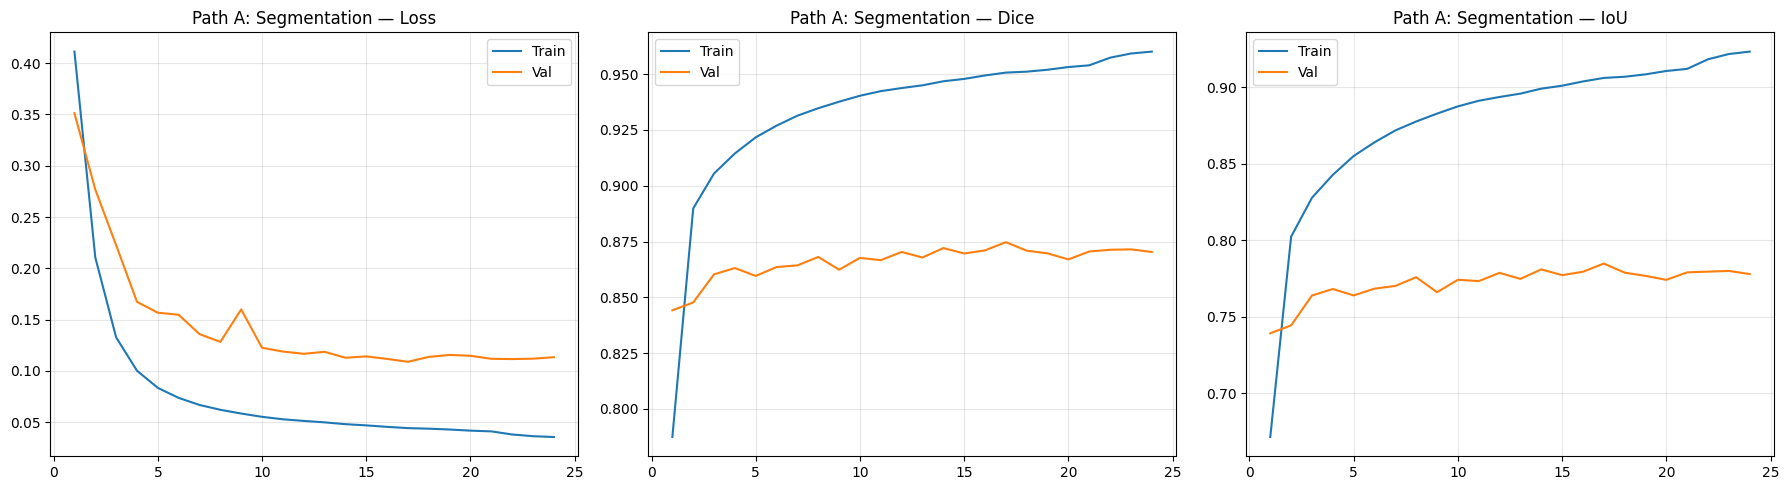

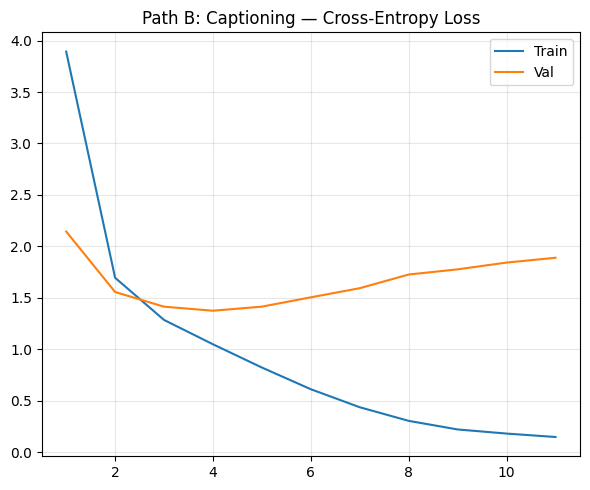

In [40]:
def plot_curves(history, title, keys_pairs):
    if not history.get(keys_pairs[0][0]):
        print(f"No history for {title}")
        return
    epochs = range(1, len(history[keys_pairs[0][0]]) + 1)
    fig, axes = plt.subplots(1, len(keys_pairs), figsize=(6 * len(keys_pairs), 5))
    if len(keys_pairs) == 1:
        axes = [axes]
    for ax, (train_k, val_k, label) in zip(axes, keys_pairs):
        ax.plot(epochs, history[train_k], label='Train')
        ax.plot(epochs, history[val_k],   label='Val')
        ax.set_title(f'{title} — {label}')
        ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

if cfg.RUN_NOTEBOOK:
    plot_curves(seg_history, "Path A: Segmentation",
                [('train_loss','val_loss','Loss'),
                 ('train_dice','val_dice','Dice'),
                 ('train_iou', 'val_iou', 'IoU')])
    plot_curves(cap_history, "Path B: Captioning",
                [('train_loss','val_loss','Cross-Entropy Loss')])

## 10. Path A — Ablation Study (With Text vs. Zeroed Text)

With Text    - Dice: 0.8247 | IoU: 0.7363
Without Text - Dice: 0.7764 | IoU: 0.6824


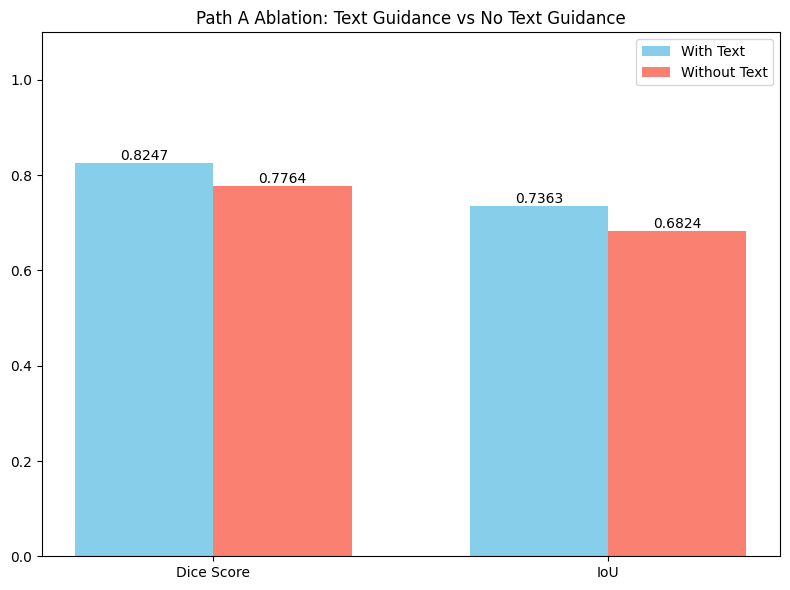

In [41]:
if cfg.RUN_NOTEBOOK:
    seg_model.eval()
    with_text_dice, no_text_dice = [], []
    with_text_iou,  no_text_iou  = [], []

    with torch.no_grad():
        for imgs, masks, embs, _, _, _ in val_loader:
            imgs, masks, embs = imgs.to(DEVICE), masks.to(DEVICE), embs.to(DEVICE)

            # With text
            logits_t  = seg_model(imgs, embs)
            preds_t   = (torch.sigmoid(logits_t) > 0.5).float()

            # Zeroed text
            logits_nt = seg_model(imgs, torch.zeros_like(embs))
            preds_nt  = (torch.sigmoid(logits_nt) > 0.5).float()

            for i in range(imgs.size(0)):
                gt = masks[i, 0].cpu().numpy()
                for preds, lst_d, lst_i in [
                    (preds_t,  with_text_dice, with_text_iou),
                    (preds_nt, no_text_dice,   no_text_iou),
                ]:
                    pr    = preds[i, 0].cpu().numpy()
                    inter = (pr * gt).sum()
                    lst_d.append((2*inter + 1e-6) / (pr.sum() + gt.sum() + 1e-6))
                    lst_i.append((inter + 1e-6) / (pr.sum() + gt.sum() - inter + 1e-6))

    m_dice_t,  m_iou_t  = np.mean(with_text_dice), np.mean(with_text_iou)
    m_dice_nt, m_iou_nt = np.mean(no_text_dice),   np.mean(no_text_iou)
    print(f"With Text    - Dice: {m_dice_t:.4f} | IoU: {m_iou_t:.4f}")
    print(f"Without Text - Dice: {m_dice_nt:.4f} | IoU: {m_iou_nt:.4f}")

    x     = np.arange(2)
    width = 0.35
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.bar(x - width/2, [m_dice_t, m_iou_t],   width, label='With Text',    color='skyblue')
    ax.bar(x + width/2, [m_dice_nt, m_iou_nt],  width, label='Without Text', color='salmon')
    ax.set_xticks(x); ax.set_xticklabels(['Dice Score', 'IoU'])
    ax.set_ylim([0, 1.1]); ax.legend()
    ax.set_title('Path A Ablation: Text Guidance vs No Text Guidance')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom')
    plt.tight_layout(); plt.show()

## 11. Path A — Qualitative Segmentation Results

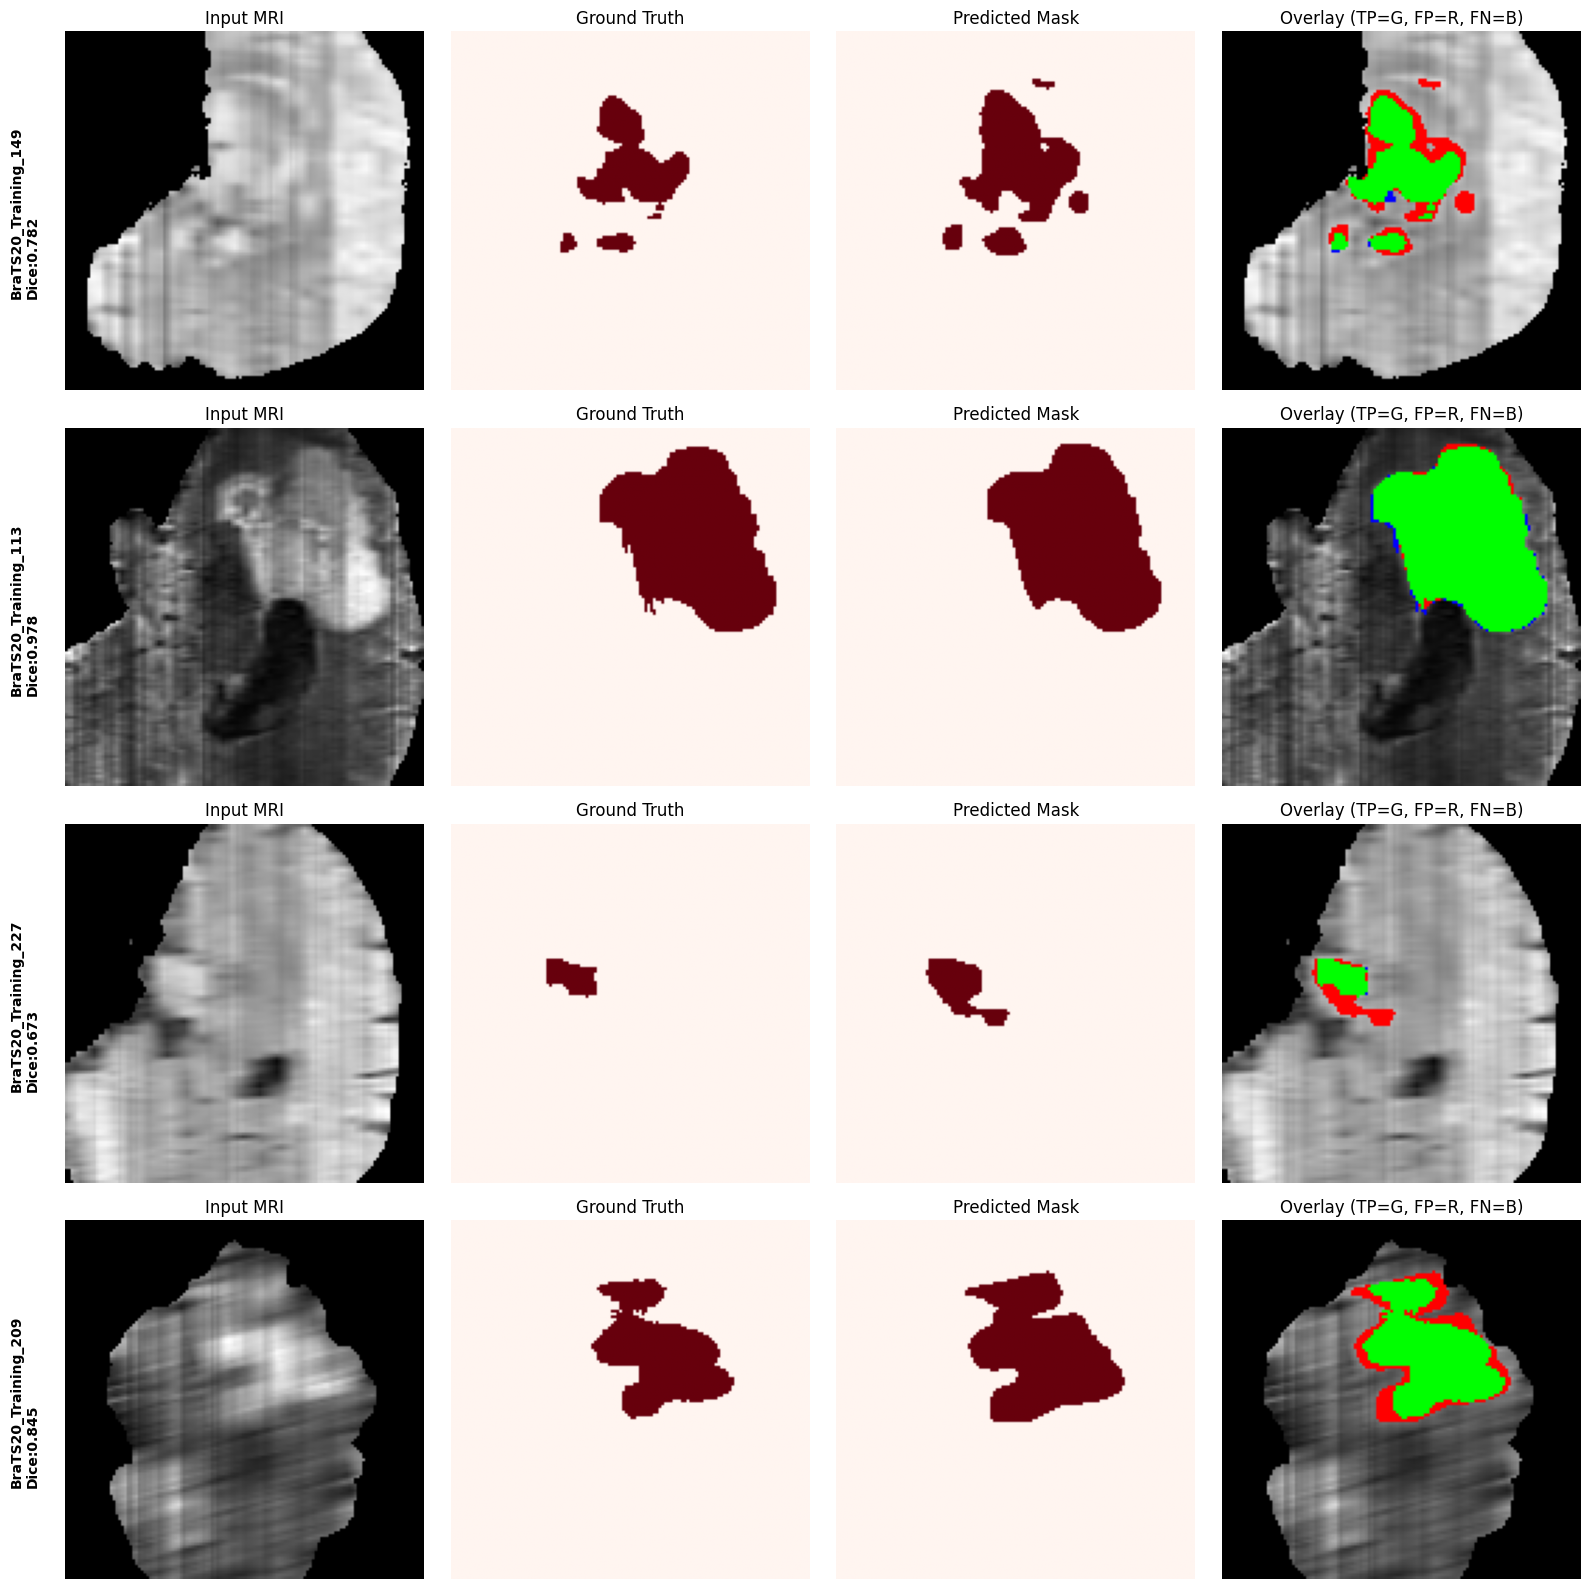

In [42]:
def plot_segmentation_results(model, dataset, num_samples=4):
    model.eval()
    indices = random.sample(range(len(dataset)), num_samples)
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4*num_samples))
    titles = ["Input MRI", "Ground Truth", "Predicted Mask", "Overlay (TP=G, FP=R, FN=B)"]

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_t, mask_t, emb_t, _, _, pid = dataset[idx]
            img  = img_t.unsqueeze(0).to(DEVICE)
            emb  = emb_t.unsqueeze(0).to(DEVICE)

            logits = model(img, emb)
            pr_np  = (torch.sigmoid(logits) > 0.5).float()[0, 0].cpu().numpy()
            img_np = img_t[0].cpu().numpy()
            gt_np  = mask_t[0].cpu().numpy()

            axes[row, 0].imshow(img_np, cmap='gray')
            axes[row, 1].imshow(gt_np, cmap='Reds')
            axes[row, 2].imshow(pr_np, cmap='Reds')

            ov = np.stack([img_np]*3, axis=-1)
            ov[pr_np == 1] = [1, 0, 0]
            ov[gt_np == 1] = [0, 0, 1]
            ov[(pr_np == 1) & (gt_np == 1)] = [0, 1, 0]
            axes[row, 3].imshow(ov)

            for col, title in enumerate(titles):
                axes[row, col].set_title(title); axes[row, col].axis('off')

            dice = (2*(pr_np*gt_np).sum()+1e-6) / (pr_np.sum()+gt_np.sum()+1e-6)
            axes[row, 0].text(-20, 64, f"{pid}\nDice:{dice:.3f}", rotation=90,
                              va='center', fontweight='bold')

    plt.tight_layout(); plt.show()

if cfg.RUN_NOTEBOOK:
    plot_segmentation_results(seg_model, val_ds, num_samples=4)

## 12. Path B — Evaluation: ROUGE & BLEU on Validation Set

In [43]:
def evaluate_captions(model, loader):
    """Generate captions and compute ROUGE/BLEU against ground truth."""
    model.eval()
    scorer = rouge_scorer.RougeScorer(['rouge1','rouge2','rougeL'], use_stemmer=True)
    smooth = SmoothingFunction().method1

    all_rouge1, all_rouge2, all_rougeL = [], [], []
    references_corpus, hypotheses_corpus = [], []
    generated_samples = []  # (img_np, gt_text, gen_text)

    with torch.no_grad():
        for imgs, _, _, _, raw_texts, _ in loader:
            imgs   = imgs.to(DEVICE)
            tokens = model.generate(imgs, SOS_IDX, EOS_IDX,
                                    max_len=cfg.MAX_SEQ_LEN)  # (B, max_len)

            for i in range(imgs.size(0)):
                gen_text = decode_ids(tokens[i].cpu().tolist())
                gt_text  = raw_texts[i]

                scores   = scorer.score(gt_text, gen_text)
                all_rouge1.append(scores['rouge1'].fmeasure)
                all_rouge2.append(scores['rouge2'].fmeasure)
                all_rougeL.append(scores['rougeL'].fmeasure)

                ref_toks = gt_text.lower().split()
                hyp_toks = gen_text.lower().split()
                references_corpus.append([ref_toks])
                hypotheses_corpus.append(hyp_toks)

                if len(generated_samples) < 4:
                    generated_samples.append((
                        imgs[i, 0].cpu().numpy(),
                        gt_text,
                        gen_text,
                    ))

    bleu4 = corpus_bleu(references_corpus, hypotheses_corpus,
                        smoothing_function=smooth)

    print("--- Path B: Text Generation Metrics (Validation Set) ---")
    print(f"  ROUGE-1 : {np.mean(all_rouge1):.4f} ± {np.std(all_rouge1):.4f}")
    print(f"  ROUGE-2 : {np.mean(all_rouge2):.4f} ± {np.std(all_rouge2):.4f}")
    print(f"  ROUGE-L : {np.mean(all_rougeL):.4f} ± {np.std(all_rougeL):.4f}")
    print(f"  BLEU-4  : {bleu4:.4f}")

    return (np.array(all_rouge1), np.array(all_rouge2),
            np.array(all_rougeL), bleu4, generated_samples)


if cfg.RUN_NOTEBOOK:
    r1, r2, rL, bleu4, gen_samples = evaluate_captions(cap_model, val_loader)

--- Path B: Text Generation Metrics (Validation Set) ---
  ROUGE-1 : 0.5377 ± 0.0552
  ROUGE-2 : 0.3013 ± 0.0590
  ROUGE-L : 0.4241 ± 0.0567
  BLEU-4  : 0.1184


## 13. Path B — Qualitative: Generated Text vs Ground Truth

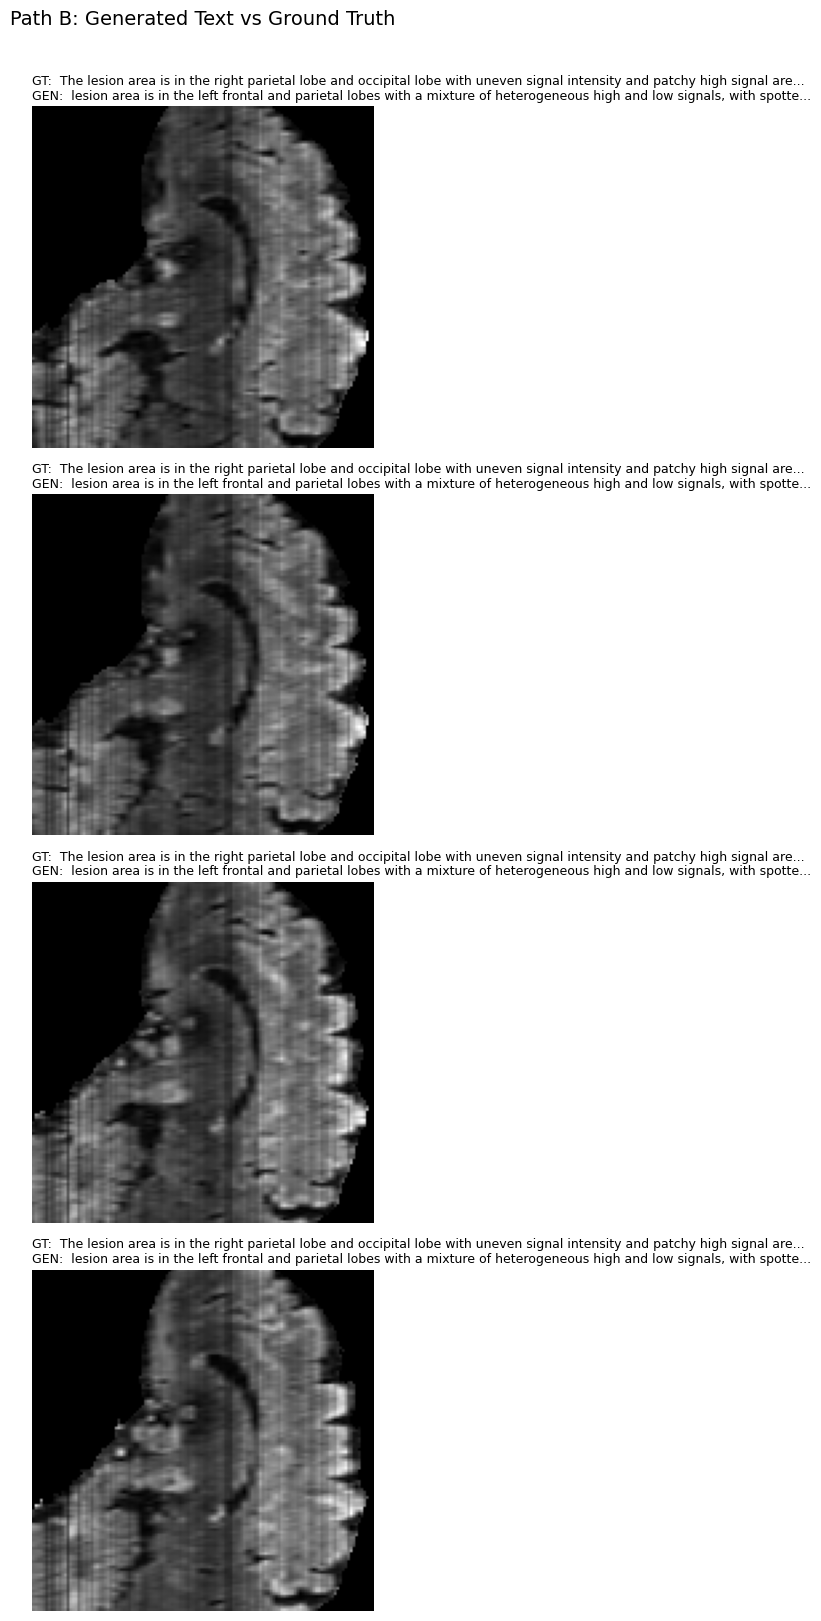

In [44]:
if cfg.RUN_NOTEBOOK:
    fig, axes = plt.subplots(len(gen_samples), 1, figsize=(14, 4 * len(gen_samples)))
    if len(gen_samples) == 1:
        axes = [axes]

    for ax, (img_np, gt_text, gen_text) in zip(axes, gen_samples):
        ax.imshow(img_np, cmap='gray')
        ax.axis('off')
        ax.set_title(
            f"GT:  {gt_text[:120]}...\nGEN: {gen_text[:120]}...",
            fontsize=9, loc='left', wrap=True
        )

    plt.suptitle("Path B: Generated Text vs Ground Truth", fontsize=14, y=1.01)
    plt.tight_layout(); plt.show()

## 14. Correlation Analysis: Path A (Dice) vs Path B (ROUGE-L)
The key insight: if both pathways genuinely understand the tumor, per-sample
Dice and ROUGE-L should be positively correlated (Spearman ρ > 0.5).

--- Computing per-sample Dice and ROUGE-L for correlation analysis ---

Spearman ρ = 0.0920  (p = 5.5040e-11)
✗ Weak correlation: pathways may be learning different features.


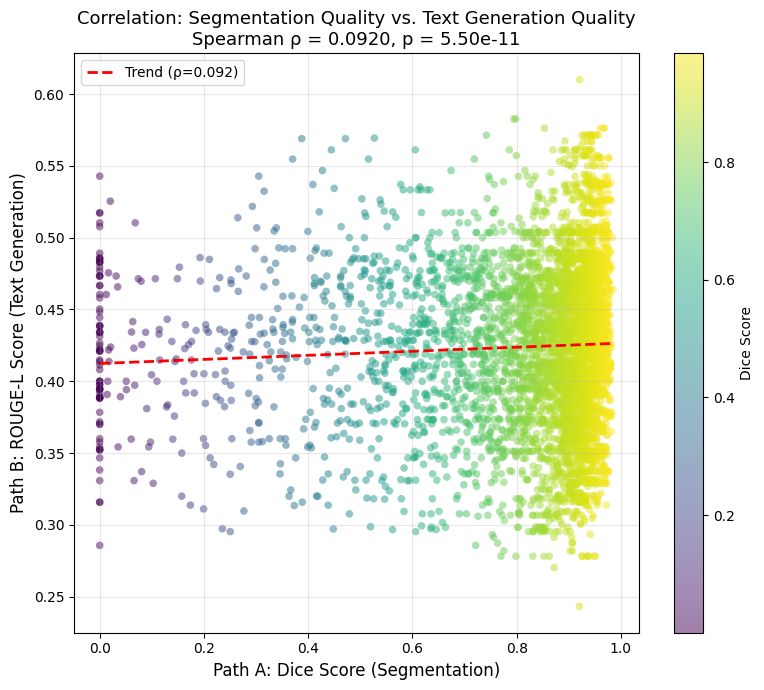

In [45]:
def compute_per_sample_metrics(seg_model, cap_model, loader):
    """Return aligned per-sample Dice and ROUGE-L arrays."""
    seg_model.eval(); cap_model.eval()
    scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

    per_dice, per_rougeL = [], []

    with torch.no_grad():
        for imgs, masks, embs, _, raw_texts, _ in loader:
            imgs, masks, embs = imgs.to(DEVICE), masks.to(DEVICE), embs.to(DEVICE)

            # Path A: segmentation
            logits = seg_model(imgs, embs)
            preds  = (torch.sigmoid(logits) > 0.5).float()

            # Path B: captioning
            tokens = cap_model.generate(imgs, SOS_IDX, EOS_IDX,
                                        max_len=cfg.MAX_SEQ_LEN)

            for i in range(imgs.size(0)):
                pr  = preds[i, 0].cpu().numpy()
                gt  = masks[i, 0].cpu().numpy()
                inter = (pr * gt).sum()
                dice  = (2*inter + 1e-6) / (pr.sum() + gt.sum() + 1e-6)
                per_dice.append(float(dice))

                gen_text = decode_ids(tokens[i].cpu().tolist())
                score    = scorer.score(raw_texts[i], gen_text)['rougeL'].fmeasure
                per_rougeL.append(float(score))

    return np.array(per_dice), np.array(per_rougeL)


if cfg.RUN_NOTEBOOK:
    print("--- Computing per-sample Dice and ROUGE-L for correlation analysis ---")
    per_dice, per_rougeL = compute_per_sample_metrics(
        seg_model, cap_model, val_loader)

    rho, pval = spearmanr(per_dice, per_rougeL)
    print(f"\nSpearman ρ = {rho:.4f}  (p = {pval:.4e})")
    if rho > 0.5:
        print("✓ Strong positive correlation: both pathways align on tumor understanding.")
    elif rho > 0.3:
        print("~ Moderate correlation: partial alignment between pathways.")
    else:
        print("✗ Weak correlation: pathways may be learning different features.")

    # Scatter plot
    fig, ax = plt.subplots(figsize=(8, 7))
    scatter = ax.scatter(per_dice, per_rougeL, alpha=0.5, c=per_dice,
                         cmap='viridis', edgecolors='none', s=30)
    plt.colorbar(scatter, ax=ax, label='Dice Score')

    # Trend line
    m, b = np.polyfit(per_dice, per_rougeL, 1)
    x_line = np.linspace(per_dice.min(), per_dice.max(), 100)
    ax.plot(x_line, m*x_line + b, 'r--', linewidth=2, label=f'Trend (ρ={rho:.3f})')

    ax.set_xlabel("Path A: Dice Score (Segmentation)", fontsize=12)
    ax.set_ylabel("Path B: ROUGE-L Score (Text Generation)", fontsize=12)
    ax.set_title("Correlation: Segmentation Quality vs. Text Generation Quality\n"
                 f"Spearman ρ = {rho:.4f}, p = {pval:.2e}", fontsize=13)
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

## 15. Final Evaluation Metrics (Both Paths)

In [46]:
from scipy.spatial.distance import directed_hausdorff

def calculate_final_metrics(seg_model, loader):
    seg_model.eval()
    all_dice, all_iou, all_prec, all_rec, all_hd = [], [], [], [], []

    with torch.no_grad():
        for imgs, masks, embs, _, _, _ in loader:
            imgs, masks, embs = imgs.to(DEVICE), masks.to(DEVICE), embs.to(DEVICE)
            logits = seg_model(imgs, embs)
            preds  = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            gts    = masks.cpu().numpy()

            for i in range(imgs.size(0)):
                pr, gt   = preds[i, 0], gts[i, 0]
                inter    = (pr * gt).sum()
                pr_sum, gt_sum = pr.sum(), gt.sum()

                dice = (2*inter + 1e-6) / (pr_sum + gt_sum + 1e-6)
                iou  = (inter + 1e-6) / (pr_sum + gt_sum - inter + 1e-6)
                prec = (inter + 1e-6) / (pr_sum + 1e-6)
                rec  = (inter + 1e-6) / (gt_sum + 1e-6)

                pr_pts = np.argwhere(pr > 0)
                gt_pts = np.argwhere(gt > 0)
                if len(pr_pts) > 0 and len(gt_pts) > 0:
                    hd = max(directed_hausdorff(pr_pts, gt_pts)[0],
                             directed_hausdorff(gt_pts, pr_pts)[0])
                else:
                    hd = 128.0

                all_dice.append(dice); all_iou.append(iou)
                all_prec.append(prec); all_rec.append(rec); all_hd.append(hd)

    print("--- PATH A: Final Segmentation Metrics (Validation Set) ---")
    print(f"  Dice Coefficient  : {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
    print(f"  IoU Score         : {np.mean(all_iou):.4f} ± {np.std(all_iou):.4f}")
    print(f"  Precision         : {np.mean(all_prec):.4f} ± {np.std(all_prec):.4f}")
    print(f"  Recall            : {np.mean(all_rec):.4f} ± {np.std(all_rec):.4f}")
    print(f"  Hausdorff Dist    : {np.mean(all_hd):.4f} ± {np.std(all_hd):.4f}")


if cfg.RUN_NOTEBOOK:
    calculate_final_metrics(seg_model, val_loader)

    print("\n--- PATH B: Final Text Generation Metrics (Validation Set) ---")
    print(f"  ROUGE-1 : {np.mean(r1):.4f} ± {np.std(r1):.4f}")
    print(f"  ROUGE-2 : {np.mean(r2):.4f} ± {np.std(r2):.4f}")
    print(f"  ROUGE-L : {np.mean(rL):.4f} ± {np.std(rL):.4f}")
    print(f"  BLEU-4  : {bleu4:.4f}")
    print(f"\n--- CROSS-PATH CORRELATION ---")
    print(f"  Spearman ρ (Dice vs ROUGE-L): {rho:.4f}  (p = {pval:.4e})")
    interp = ("Strong alignment" if rho > 0.5
              else "Moderate alignment" if rho > 0.3
              else "Weak alignment")
    print(f"  Interpretation: {interp} between segmentation and text generation quality.")

--- PATH A: Final Segmentation Metrics (Validation Set) ---
  Dice Coefficient  : 0.8247 ± 0.1930
  IoU Score         : 0.7363 ± 0.2151
  Precision         : 0.8473 ± 0.1818
  Recall            : 0.8466 ± 0.2079
  Hausdorff Dist    : 14.1768 ± 15.4976

--- PATH B: Final Text Generation Metrics (Validation Set) ---
  ROUGE-1 : 0.5377 ± 0.0552
  ROUGE-2 : 0.3013 ± 0.0590
  ROUGE-L : 0.4241 ± 0.0567
  BLEU-4  : 0.1184

--- CROSS-PATH CORRELATION ---
  Spearman ρ (Dice vs ROUGE-L): 0.0920  (p = 5.5040e-11)
  Interpretation: Weak alignment between segmentation and text generation quality.
